# 03 - History matching: find the parameters that reproduce the real field
**What this notebook does:** uses the proxy to try thousands of parameter combinations and keeps those whose 1998-2008 curves are closest to the real field. Output: the **10 best parameter sets**.

**Key idea - the misfit:** one number that says how far a predicted curve is from the observed one. For every quarter we take (predicted - observed), divide by the measurement error we allow (sigma), square it, and average. 0 = perfect. Smaller is better; the number is mainly useful for comparing candidates with each other.

**How to run:** Runtime -> Run all (about 5 minutes). Needs notebook 02.

In [1]:
# SETUP - run this cell first, every time you open the notebook.
# It connects Google Drive, installs one extra package and loads our helper code.
import os, sys, subprocess, importlib
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/DWC26'          # the shared team folder
except ImportError:                                 # (only used when running outside Colab)
    BASE = os.environ.get('DWC_BASE', 'DWC26')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'python-calamine'], check=False, capture_output=True)
sys.path.insert(0, f'{BASE}/notebooks')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import dwc_utils as du; importlib.reload(du)
P = du.get_paths(BASE)
pd.set_option('display.float_format', lambda x: f'{x:,.4g}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('Ready. Project folder:', BASE)

Mounted at /content/drive
Ready. Project folder: /content/drive/MyDrive/DWC26


In [2]:
import joblib
du.require(f"{P['PROC']}/proxy.joblib", 'notebook 02')
A = np.load(f"{P['PROC']}/arrays.npz")
grid = pd.to_datetime(A['grid']); gx = du.day_number(grid)
params = pd.read_parquet(f"{P['PROC']}/params.parquet").set_index('case_id').loc[A['case_ids']].reset_index()
Y = {v: A[v] for v in du.CUMS}
OBS = {v: A['obs_' + v] for v in du.CUMS}
M = joblib.load(f"{P['PROC']}/proxy.joblib"); proxy, lo, hi = M['proxy'], M['lo'], M['hi']
predict = lambda S: {v: proxy[v].predict(S) for v in du.CUMS}
print('Loaded proxy:', M['method'])

Loaded proxy: gp


## Settings (you may change these and run all again)
- `WEIGHTS`: how much each series counts (0 = ignored). By default we match the three cumulative curves. You can also switch on the quarterly oil and water rates (set them to 0.2-1): rates show the *shape* more sharply, but they are calculated from differences of the cumulatives, so measurement noise gets amplified. Compare both and report which you used.
- `SIGMA_FRAC`: allowed measurement error, as a share of each series' largest value. 0.03 = 3%.

Try one or two other settings and write in the slides whether the answer changed. That shows the result is robust.

In [3]:
WEIGHTS = {'oil_cum': 1, 'gas_cum': 1, 'water_cum': 1, 'oil_rate': 0, 'water_rate': 0}
SIGMA_FRAC = 0.03
misfit = du.Misfit(gx, OBS, WEIGHTS, SIGMA_FRAC)

## Step 1 - Which of the 100 real simulator runs is closest?
This uses the real simulator results, with no proxy involved, so it's a safe sanity check. The best real runs show roughly where the answer lies.

,case_id,fault_trans,poro_mult,perm_mult,aquifer_pv,misfit
5,6,0.05769,1.358,2.468,119.8,0.0532
96,97,0.05192,1.346,5.409,153.9,0.06008
75,76,0.1079,1.383,1.64,182.2,0.06122
10,11,0.125,1.354,7.338,188.1,0.06263
39,40,0.1443,1.354,4.961,132.5,0.06366
72,73,0.08256,1.354,1.475,93.32,0.06701
49,50,0.1003,1.357,7.459,170.7,0.08195
19,20,0.06182,1.361,5.078,123.4,0.1025
3,4,0.1455,1.364,8.602,158.1,0.1754
25,26,0.09804,1.346,1.943,53.95,0.1789


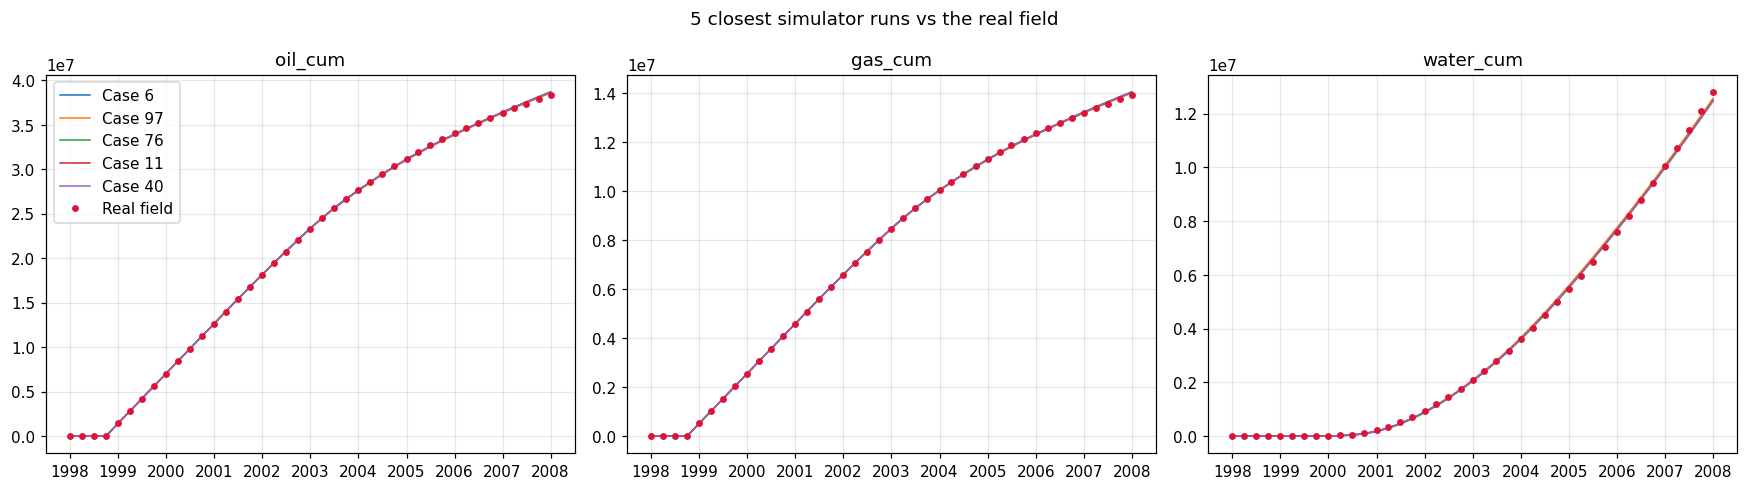

In [4]:
params['misfit'] = misfit(Y)
top = params.sort_values('misfit').head(10)
display(top[['case_id'] + du.PARAMS + ['misfit']])
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, v in zip(ax, du.CUMS):
    for _, r in top.head(5).iterrows():
        a.plot(grid, Y[v][params.index[params.case_id == r.case_id][0]], lw=1, label=f'Case {int(r.case_id)}')
    a.plot(grid, OBS[v], 'o', color='crimson', ms=3.5, label='Real field'); a.set_title(v)
ax[0].legend(); fig.suptitle('5 closest simulator runs vs the real field'); fig.tight_layout()
fig.savefig(f"{P['FIG']}/07_closest_real_cases.png", bbox_inches='tight'); plt.show()

## Step 2 - Scan 16,384 combinations with the proxy
**Sobol sampling** spreads the test points evenly over all possible values of the 4 parameters. The proxy predicts each one in a fraction of a second; the simulator would need months.

In [5]:
from scipy.stats import qmc
S = qmc.Sobol(4, seed=0).random(2 ** 14)          # 16,384 points between 0 and 1
J = misfit(predict(S))
print(f'Best misfit in the scan: {J.min():.3f}   (best real simulator run: {params.misfit.min():.3f})')

Best misfit in the scan: 0.047   (best real simulator run: 0.053)


## Step 3 - Fine-tune the best answer (differential evolution)
**Differential evolution** keeps a population of guesses and improves it step by step, like natural selection. We run it 3 times with different random starts: if all 3 land in the same place, the answer is reliable.

In [6]:
from scipy.optimize import differential_evolution
f = lambda s: misfit(predict(s[None]))[0]
runs = []
for seed in [0, 1, 2]:
    r = differential_evolution(f, [(0, 1)] * 4, seed=seed, tol=1e-7, maxiter=150, polish=True)
    runs.append(dict(zip(du.PARAMS, du.unscale_inputs(r.x, lo, hi)), misfit=r.fun, seed=seed))
runs = pd.DataFrame(runs); display(runs)

,fault_trans,poro_mult,perm_mult,aquifer_pv,misfit,seed
0,0.15,1.381,1.084,188,0.04653,0
1,0.15,1.381,1.084,188,0.04653,1
2,0.15,1.381,1.084,188,0.04653,2


## Step 4 - Choose the 10 best, but different from each other
We take the best 1% of all combinations (the "acceptable" ones), split them into 10 groups of similar combinations (**K-means clustering**), and keep the best one from each group. That way the 10 cases show the real range of possibilities instead of 10 copies of the same answer.

In [7]:
from sklearn.cluster import KMeans
S_all = np.vstack([S] + [du.scale_inputs(runs[du.PARAMS].values, lo, hi)[0]])
J_all = misfit(predict(S_all))
ok = J_all <= np.quantile(J_all, 0.01)
km = KMeans(10, n_init=10, random_state=0).fit(S_all[ok])
pick = np.array([np.where(ok)[0][km.labels_ == c][np.argmin(J_all[ok][km.labels_ == c])] for c in range(10)])
pick = pick[np.argsort(J_all[pick])]                          # best first
best10_s = S_all[pick]
BEST10 = pd.DataFrame(du.unscale_inputs(best10_s, lo, hi), columns=du.PARAMS)
BEST10.insert(0, 'rank', range(1, 11)); BEST10['misfit'] = J_all[pick]
BEST10.to_csv(f"{P['OUT']}/best10_parameters.csv", index=False)
np.save(f"{P['PROC']}/best10_scaled.npy", best10_s)
display(BEST10)

,rank,fault_trans,poro_mult,perm_mult,aquifer_pv,misfit
0,1,0.15,1.381,1.084,188,0.04653
1,2,0.1051,1.385,0.8784,195.6,0.04717
2,3,0.06257,1.377,1.017,174.6,0.04768
3,4,0.07615,1.37,1.555,147.9,0.04799
4,5,0.1325,1.375,1.791,181,0.04802
5,6,0.1215,1.37,1.314,127.6,0.04962
6,7,0.06873,1.36,2.49,141.5,0.05119
7,8,0.06086,1.364,2.506,168.4,0.05131
8,9,0.1464,1.355,5.944,188.9,0.05269
9,10,0.1481,1.354,2.757,107,0.0529


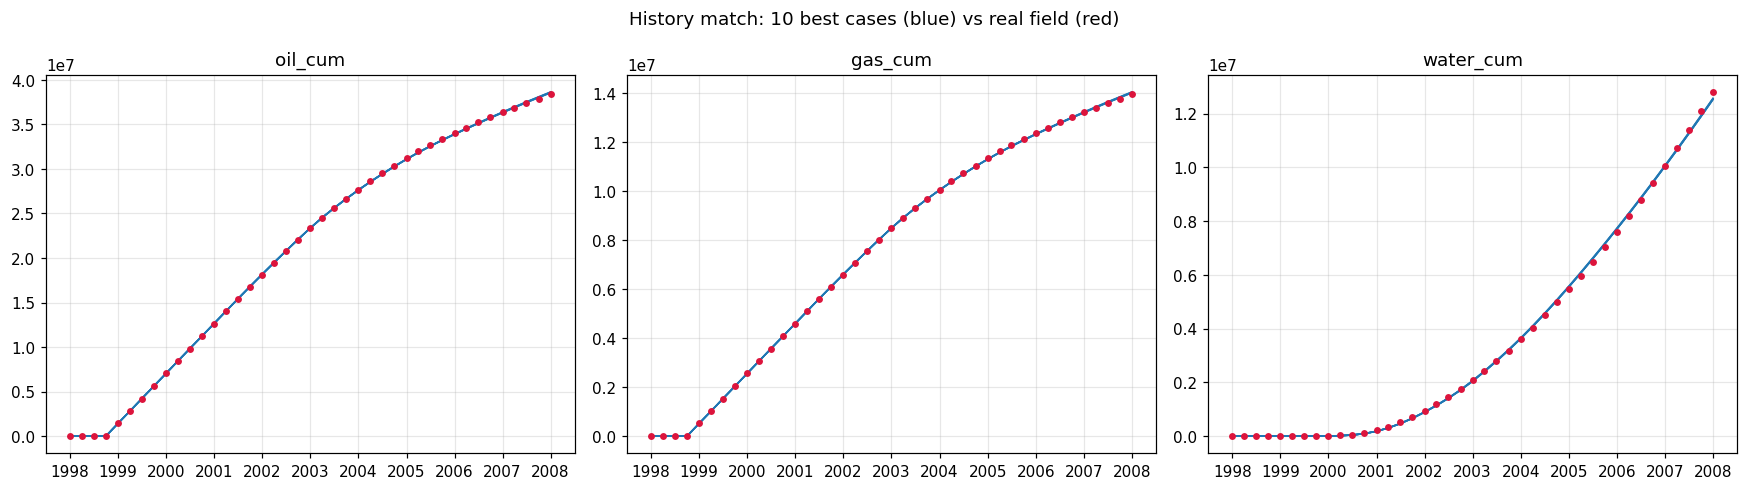

In [8]:
curves10 = predict(best10_s)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, v in zip(ax, du.CUMS):
    a.plot(grid, curves10[v].T, color='tab:blue', alpha=0.6, lw=1)
    a.plot(grid, OBS[v], 'o', color='crimson', ms=3.5); a.set_title(v)
fig.suptitle('History match: 10 best cases (blue) vs real field (red)'); fig.tight_layout()
fig.savefig(f"{P['FIG']}/08_history_match.png", bbox_inches='tight'); plt.show()

## Step 5 - What does history tell us, and what can't it tell us?
Histograms of each parameter among the acceptable combinations. A **narrow** histogram means the history pins that parameter down. A histogram **spread over the whole range** means history can't tell, and that parameter becomes a risk for the forecast. This is a strong business insight for the slides.

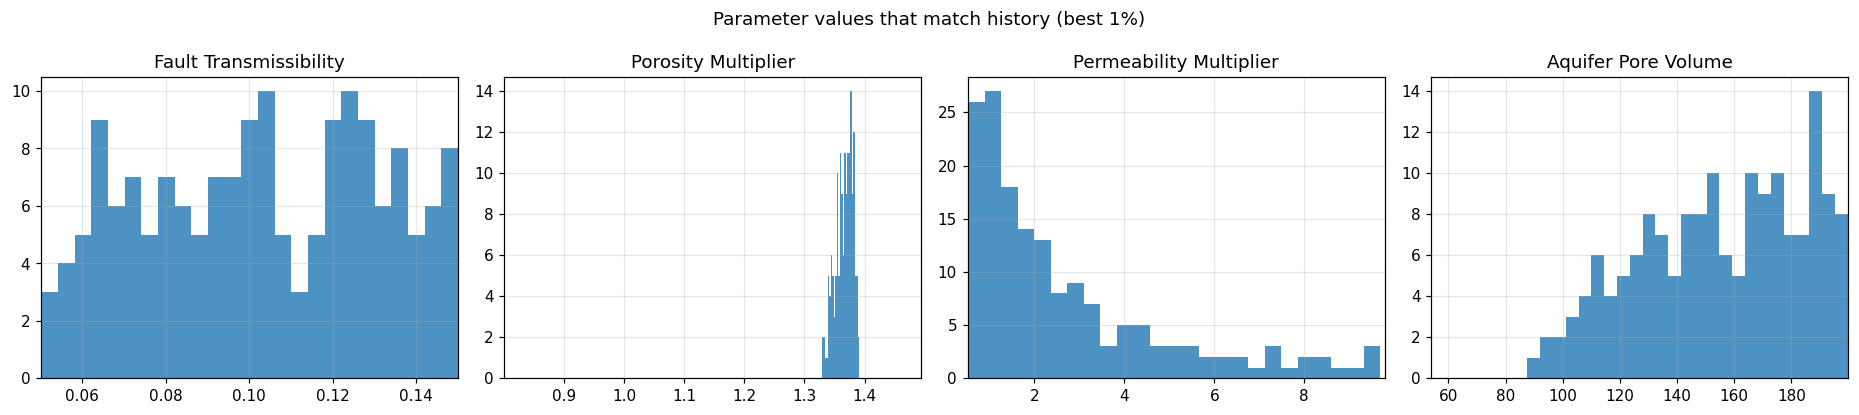

- Fault Transmissibility: matching values span 75% of the possible range -> poorly constrained - a forecast risk
- Porosity Multiplier: matching values span 5% of the possible range -> well pinned down by history
- Permeability Multiplier: matching values span 59% of the possible range -> partly constrained
- Aquifer Pore Volume: matching values span 53% of the possible range -> partly constrained


In [9]:
acc = pd.DataFrame(du.unscale_inputs(S_all[ok], lo, hi), columns=du.PARAMS)
full = params[du.PARAMS]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, p in zip(ax, du.PARAMS):
    a.hist(acc[p], bins=25, color='tab:blue', alpha=0.8); a.set_xlim(full[p].min(), full[p].max())
    a.set_title(du.PARAM_LABELS[p])
fig.suptitle('Parameter values that match history (best 1%)'); fig.tight_layout()
fig.savefig(f"{P['FIG']}/09_parameter_uncertainty.png", bbox_inches='tight'); plt.show()
for p in du.PARAMS:
    width = (acc[p].quantile(0.9) - acc[p].quantile(0.1)) / (full[p].max() - full[p].min())
    verdict = 'well pinned down by history' if width < 0.3 else 'poorly constrained - a forecast risk' if width > 0.6 else 'partly constrained'
    print(f'- {du.PARAM_LABELS[p]}: matching values span {width:.0%} of the possible range -> {verdict}')
samples = pd.DataFrame(du.unscale_inputs(S_all, lo, hi), columns=du.PARAMS).assign(misfit=J_all, acceptable=ok)
samples.sample(min(4000, len(samples)), random_state=0).to_csv(f"{P['PBI']}/hm_samples.csv", index=False)

**Next: notebook 04.**